In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import os

# Mode (matches the directory name in distribution_data and pmf_data)
mode = "total"

# Répertoires
pmf_dir = f'../data/pmf_data/{mode}/'
dist_dir = f'../data/distribution_data/{mode}/'
output_dir = '../plot/'

# Constantes
k_B = 0.008314  # kJ/(mol*K)
T = 303.15
epsilon = 1e-5

In [2]:
def free_energy(pKa, charge):
    """Calcule l'énergie libre de référence pour les formes neutres"""
    R = 8.314e-3  # kJ/mol.K
    T = 302.3545798089109  # K
    pH = 7.0
    return -charge * R * T * np.log(10) * (pKa - pH)


def get_ref_per_acid(acid):
    """
    Retourne la correction d'énergie libre pour la forme neutre.
    Source: Platzer et al. (2014)
    pKa: ARG 13.9, LYS 10.34, ASP 3.86, GLU 4.34, HIS 6.45, CYS 8.49, TYR 9.76
    """
    # Pour la ref aux résidus chargés
    neutrals = ['SCHE', 'SCHD', 'SCKN', 'SCRN', 'SCDN', 'SCEN', 'SCC', 'SCY']
    pKas = [6.45, 6.45, 10.34, 13.9, 3.86, 4.34, 8.49, 9.76]
    charges = [1, 1, 1, 1, -1, -1, -1, -1]
    
    if acid in neutrals:
        return free_energy(pKas[neutrals.index(acid)], charges[neutrals.index(acid)])
    return 0


def PMF_residue(acid):
    """
    Charge directement le fichier PMF pré-calculé.
    Fichier: pmf_data/{mode}/{acid}/pmf_{acid}.dat
    Colonnes: z, mean, se  ->  renommées en x, PMF_mean, std_error
    """
    fpath = os.path.join(pmf_dir, acid.lower(), f'pmf_{acid.lower()}.dat')
    df = pd.read_table(fpath, sep=r"\s+")
    df.rename(columns={'z': 'x', 'mean': 'PMF_mean', 'se': 'std_error'}, inplace=True)
    return df


def find_zero_density_limit(acid):
    """
    Trouve la valeur |z| la plus haute où la densité moyenne est 0.
    Lit le fichier summary_{acid}.dat (colonnes: z, mean, se).
    
    Returns:
        float: la limite z en dessous de laquelle les données sont invalides (densité nulle)
    """
    fpath = os.path.join(dist_dir, acid.lower(), f'summary_{acid.lower()}.dat')
    if not os.path.isfile(fpath):
        print(f"Attention: {fpath} non trouvé pour {acid}")
        return 0.0
    
    df = pd.read_table(fpath, sep=r'\s+')
    df['z_abs'] = df['z'].abs()
    # Trouver les |z| < 20 où la densité moyenne est nulle
    zeros = df[(df['mean'] == 0.0) & (df['z_abs'] < 20.0)]['z_abs'].values
    
    if len(zeros) == 0:
        return 0.0
    
    return float(zeros.max())


def get_interval_btw_PMF(ref_data, new_data, correction, z_limit_ref=0.0, z_limit_new=0.0):
    """
    Calcule la différence d'énergie libre ΔG = PMF_new - PMF_ref + correction
    et propage l'erreur: SE = sqrt(SE_ref² + SE_new²)
    
    Args:
        ref_data: DataFrame avec x, PMF_mean, std_error (forme neutre)
        new_data: DataFrame avec x, PMF_mean, std_error (forme chargée)
        correction: correction d'énergie libre
        z_limit_ref: limite z pour la forme de référence (points < z_limit sont exclus)
        z_limit_new: limite z pour la nouvelle forme (points < z_limit sont exclus)
    
    Returns:
        DataFrame avec x, DG_mean, DG_std_error
    """
    # Fusionner sur x
    merged = pd.merge(ref_data, new_data, on='x', suffixes=('_ref', '_new'))
    
    # Filtrer les points en dessous des limites de densité nulle
    z_limit = max(z_limit_ref, z_limit_new)
    if z_limit > 0:
        merged = merged[merged['x'] > z_limit].copy()
    
    # Calcul de ΔG
    merged['DG_mean'] = merged['PMF_mean_new'] - merged['PMF_mean_ref'] + correction
    
    # Propagation de l'erreur: sqrt(SE_ref² + SE_new²)
    merged['DG_std_error'] = np.sqrt(merged['std_error_ref']**2 + merged['std_error_new']**2)
    
    return merged[['x', 'DG_mean', 'DG_std_error']]

In [3]:
# Définition des acides aminés
aa_name = ['SCRN', 'SCR', 'SCKN', 'SCK', 'SCHE', 'SCHP',
           'SCDN', 'SCD', 'SCEN', 'SCE', 'SCC', 'SCCM', 'SCY', 'SCYM']

aa_symbol = ['ARGN', 'ARG', 'LYSN', 'LYS', 'HSE', 'HIS',
             'ASPN', 'ASP', 'GLUN', 'GLU', 'CYSN', 'CYS', 'TYRN', 'TYR']

aa_charge = [0, 1, 0, 1, 0, 1, 0, -1, 0, -1, 0, -1, 0, -1]


def pKa_func(DG, charge):
    """Convertit une différence d'énergie libre en pKa"""
    R = 8.314e-3  # kJ/mol.K
    T = 302.3545798089109  # K
    pH = 7.0
    return -DG / (charge * R * T * np.log(10)) + pH


def compute_pKa_dataframe(filter_plateau=False):
    """
    Calcule les pKa pour tous les acides aminés à partir des fichiers PMF pré-calculés.
    
    Args:
        filter_plateau: Si True, retire les points où la densité est nulle
                        (déterminé depuis les fichiers de distribution)
    
    Returns:
        DataFrame avec x, pKa et std pour chaque acide aminé
    """
    results_list = []
    
    for i in range(0, len(aa_name), 2):
        # Charger les PMF pré-calculés
        ref_data = PMF_residue(aa_name[i])      # Forme neutre
        new_data = PMF_residue(aa_name[i + 1])  # Forme chargée
        
        acid_s = aa_symbol[i + 1]
        charge = aa_charge[i + 1]
        correction = get_ref_per_acid(aa_name[i])
        
        # Trouver les limites z où la densité devient nulle
        if filter_plateau:
            z_limit_ref = find_zero_density_limit(aa_name[i])
            z_limit_new = find_zero_density_limit(aa_name[i + 1])
        else:
            z_limit_ref = 0.0
            z_limit_new = 0.0
        
        # Calcul de ΔG avec propagation d'erreur
        DG = get_interval_btw_PMF(ref_data, new_data, correction, 
                                   z_limit_ref=z_limit_ref, z_limit_new=z_limit_new)
        
        # Conversion en pKa
        DG['pKa'] = pKa_func(DG['DG_mean'], charge)
        # Propagation de l'erreur pour pKa: |dpKa/dDG| * SE_DG
        R = 8.314e-3
        T = 302.3545798089109
        DG['pKa_std'] = np.abs(1 / (charge * R * T * np.log(10))) * DG['DG_std_error']
        
        # Renommer les colonnes pour cet acide
        DG_renamed = DG[['x', 'pKa', 'pKa_std']].rename(columns={
            'pKa': f'pKa_{acid_s}',
            'pKa_std': f'std_{acid_s}'
        })
        results_list.append(DG_renamed)
    
    # Fusionner tous les résultats sur x
    result = results_list[0]
    for df in results_list[1:]:
        result = pd.merge(result, df, on='x', how='outer')
    
    return result.sort_values('x').reset_index(drop=True)


# Calcul des deux DataFrames
print("Calcul des pKa (tous points)...")
df_e = compute_pKa_dataframe(filter_plateau=False)  # Tous les points (avec plateau)

print("Calcul des pKa (sans plateau - basé sur densité nulle)...")
df_0 = compute_pKa_dataframe(filter_plateau=True)   # Sans les points au plateau

# Affichage des limites trouvées
print("\n=== Limites de densité nulle trouvées ===")
for i in range(0, len(aa_name), 2):
    z_ref = find_zero_density_limit(aa_name[i])
    z_new = find_zero_density_limit(aa_name[i + 1])
    print(f"{aa_symbol[i+1]}: ref ({aa_name[i]}) z_min={z_ref:.1f} Å, new ({aa_name[i+1]}) z_min={z_new:.1f} Å")

print("\n=== Résumé des calculs ===")
print("PMF chargés depuis fichiers .dat pré-calculés")
print("Erreur standard: sqrt(SE_ref² + SE_new²)")

print("\nExtrait pour z ∈ [0, 20] Å (tous points):")
display(df_e[(df_e['x'] > 0) & (df_e['x'] < 20)])

print("\nExtrait pour z ∈ [0, 20] Å (sans plateau):")
display(df_0[(df_0['x'] > 0) & (df_0['x'] < 20)])

Calcul des pKa (tous points)...
Calcul des pKa (sans plateau - basé sur densité nulle)...

=== Limites de densité nulle trouvées ===
ARG: ref (SCRN) z_min=0.5 Å, new (SCR) z_min=5.5 Å
LYS: ref (SCKN) z_min=0.0 Å, new (SCK) z_min=4.5 Å
HIS: ref (SCHE) z_min=5.5 Å, new (SCHP) z_min=8.5 Å
ASP: ref (SCDN) z_min=0.0 Å, new (SCD) z_min=13.5 Å
GLU: ref (SCEN) z_min=0.0 Å, new (SCE) z_min=11.5 Å
CYS: ref (SCC) z_min=0.0 Å, new (SCCM) z_min=11.5 Å
TYR: ref (SCY) z_min=0.0 Å, new (SCYM) z_min=8.5 Å

=== Résumé des calculs ===
PMF chargés depuis fichiers .dat pré-calculés
Erreur standard: sqrt(SE_ref² + SE_new²)

Extrait pour z ∈ [0, 20] Å (tous points):


,x,pKa_ARG,std_ARG,pKa_LYS,std_LYS,pKa_HIS,std_HIS,pKa_ASP,std_ASP,pKa_GLU,std_GLU,pKa_CYS,std_CYS,pKa_TYR,std_TYR
0,0.5,13.413267,0.036028,7.161776,0.029318,6.432885,0.003479,4.948443,0.143534,6.508488,0.067184,13.200683,0.055200,13.262507,0.156237
1,1.5,13.287223,0.077659,7.167264,0.028658,6.424064,0.009297,4.936870,0.132047,6.496647,0.068418,13.193226,0.054662,13.343355,0.143781
2,2.5,13.047175,0.089510,7.173627,0.027543,6.432885,0.003479,4.997426,0.100200,6.534581,0.062663,13.171637,0.054176,13.496758,0.142262
3,3.5,12.597490,0.089186,7.177940,0.025752,6.410145,0.022809,5.205560,0.077242,6.666424,0.049999,13.137011,0.053876,13.800127,0.136502
4,4.5,12.000719,0.083285,7.213337,0.051957,6.386805,0.029031,5.537748,0.067191,6.944101,0.037364,13.097686,0.053113,14.194119,0.126723
5,5.5,11.484600,0.080037,7.297179,0.109831,6.298357,0.048009,5.935955,0.052362,7.285584,0.030189,13.061173,0.052584,14.586718,0.121769
6,6.5,11.054636,0.100620,7.550256,0.143683,6.206532,0.067671,6.341012,0.040795,7.628695,0.031902,13.046778,0.052483,14.945456,0.122030
7,7.5,11.114013,0.105403,7.964055,0.086539,5.901174,0.065261,6.710028,0.032499,7.934652,0.030234,13.058870,0.051555,15.252621,0.122920
8,8.5,11.556143,0.085724,8.392712,0.044614,5.390747,0.068075,7.042197,0.029856,8.193800,0.029376,13.097623,0.050829,15.404255,0.131962
9,9.5,11.928602,0.072398,8.788494,0.038912,5.113486,0.101940,7.314031,0.028466,8.398049,0.029597,13.153276,0.048941,15.399323,0.161197



Extrait pour z ∈ [0, 20] Å (sans plateau):


,x,pKa_ARG,std_ARG,pKa_LYS,std_LYS,pKa_HIS,std_HIS,pKa_ASP,std_ASP,pKa_GLU,std_GLU,pKa_CYS,std_CYS,pKa_TYR,std_TYR
0,5.5,NaN,NaN,7.297179,0.109831,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
1,6.5,11.054636,0.100620,7.550256,0.143683,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2,7.5,11.114013,0.105403,7.964055,0.086539,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
3,8.5,11.556143,0.085724,8.392712,0.044614,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
4,9.5,11.928602,0.072398,8.788494,0.038912,5.113486,0.101940,NaN,NaN,NaN,NaN,NaN,NaN,15.399323,0.161197
5,10.5,12.287170,0.056061,9.105436,0.037009,5.289044,0.114433,NaN,NaN,NaN,NaN,NaN,NaN,15.180383,0.152876
6,11.5,12.594614,0.051755,9.372584,0.033405,5.631809,0.088471,NaN,NaN,NaN,NaN,NaN,NaN,14.688851,0.141630
7,12.5,12.851143,0.048941,9.603968,0.032382,5.881587,0.062230,NaN,NaN,8.623472,0.035844,13.054468,0.067302,14.189787,0.142874
8,13.5,13.085167,0.046832,9.799984,0.030489,6.072431,0.050986,NaN,NaN,8.346783,0.114464,12.727877,0.097969,13.748241,0.141683
9,14.5,13.297574,0.045351,9.961268,0.029301,6.250677,0.047052,7.414361,0.087413,7.937478,0.125744,12.126829,0.074265,13.302375,0.139536


In [7]:
# Sauvegarde d'un tableau pKa(z) avec une colonne par résidu (SCRN, SCR, SCKN, SCK, ...)
# Les points du plateau (densité nulle) NE sont PAS remplacés par les pKa incertains :
# on prolonge avec le dernier pKa fiable (celui juste au bord du plateau), i.e. pKa constant.

# On part de df_0 (déjà filtré : plateau retiré) puis on complète les x manquants
# avec la grille complète issue de df_e, en propageant vers z décroissant (bfill).
pKa_cols_symbol = [f'pKa_{s}' for s in aa_symbol[1::2]]  # pKa_ARG, pKa_LYS, ...

# Grille complète de z (tous les points, y compris ceux du plateau)
grid = df_e[['x']].copy()

# Reindexer df_0 sur la grille complète, puis back-fill vers les petits z
df_const = pd.merge(grid, df_0[['x'] + pKa_cols_symbol], on='x', how='left')
df_const = df_const.sort_values('x').reset_index(drop=True)
df_const[pKa_cols_symbol] = df_const[pKa_cols_symbol].bfill()

# Construire le tableau final avec une colonne par aa_name (SCRN=SCR, SCKN=SCK, ...)
table = pd.DataFrame({'z': df_const['x'].values})
for i in range(0, len(aa_name), 2):
    sym = aa_symbol[i + 1]  # ex: ARG
    pKa_vals = df_const[f'pKa_{sym}'].values
    table[aa_name[i]] = pKa_vals      # forme neutre (SCRN, SCKN, ...)
    table[aa_name[i + 1]] = pKa_vals  # forme chargée (SCR, SCK, ...)

# Réordonner : z, SCRN, SCR, SCKN, SCK, SCHE, SCHP, SCDN, SCD, SCEN, SCE, SCC, SCCM, SCY, SCYM
table = table[['z'] + list(aa_name)]

# Retirer les z > 51 Å (zone d'eau lointaine sans intérêt biologique)
table = table[table['z'] <= 51].reset_index(drop=True)

out_path = os.path.join(dist_dir, f'..', f'pKa_table_{mode}.csv')
out_path = os.path.normpath(out_path)
table.to_csv(out_path, index=False, float_format='%.4f')
print(f"Tableau pKa enregistré : {out_path}")
display(table.head())
display(table.tail())


Tableau pKa enregistré : ..\data\distribution_data\pKa_table_total.csv


,z,SCRN,SCR,SCKN,SCK,SCHE,SCHP,SCDN,SCD,SCEN,SCE,SCC,SCCM,SCY,SCYM
0,0.5,11.054636,11.054636,7.297179,7.297179,5.113486,5.113486,7.414361,7.414361,8.623472,8.623472,13.054468,13.054468,15.399323,15.399323
1,1.5,11.054636,11.054636,7.297179,7.297179,5.113486,5.113486,7.414361,7.414361,8.623472,8.623472,13.054468,13.054468,15.399323,15.399323
2,2.5,11.054636,11.054636,7.297179,7.297179,5.113486,5.113486,7.414361,7.414361,8.623472,8.623472,13.054468,13.054468,15.399323,15.399323
3,3.5,11.054636,11.054636,7.297179,7.297179,5.113486,5.113486,7.414361,7.414361,8.623472,8.623472,13.054468,13.054468,15.399323,15.399323
4,4.5,11.054636,11.054636,7.297179,7.297179,5.113486,5.113486,7.414361,7.414361,8.623472,8.623472,13.054468,13.054468,15.399323,15.399323


,z,SCRN,SCR,SCKN,SCK,SCHE,SCHP,SCDN,SCD,SCEN,SCE,SCC,SCCM,SCY,SCYM
46,46.5,13.905968,13.905968,10.343918,10.343918,6.447335,6.447335,3.858649,3.858649,4.339022,4.339022,8.489004,8.489004,9.765176,9.765176
47,47.5,13.904546,13.904546,10.348170,10.348170,6.454747,6.454747,3.862348,3.862348,4.340629,4.340629,8.502632,8.502632,9.757244,9.757244
48,48.5,13.904403,13.904403,10.345724,10.345724,6.455358,6.455358,3.865575,3.865575,4.345629,4.345629,8.488111,8.488111,9.739892,9.739892
49,49.5,13.910482,13.910482,10.341824,10.341824,6.453289,6.453289,3.865494,3.865494,4.342184,4.342184,8.493271,8.493271,9.741385,9.741385
50,50.5,13.908206,13.908206,10.338263,10.338263,6.458480,6.458480,3.862274,3.862274,4.346773,4.346773,8.490339,8.490339,9.714214,9.714214


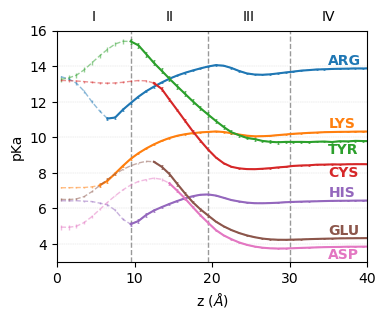

In [5]:
# Plot des pKa
color = plt.rcParams['axes.prop_cycle'].by_key()['color']
plt.figure(figsize=(4, 3))
list_aa = ['ARG', 'LYS', 'TYR', 'CYS', 'HIS', 'GLU', 'ASP']

for i, name in enumerate(list_aa):
    # Données sans plateau (ligne pleine)
    mask_0 = df_0['x'].notna() & df_0[f'pKa_{name}'].notna()
    x1 = df_0.loc[mask_0, 'x']
    y1 = df_0.loc[mask_0, f'pKa_{name}']
    e1 = df_0.loc[mask_0, f'std_{name}']
    
    # Données avec plateau (ligne pointillée)
    mask_e = df_e['x'].notna() & df_e[f'pKa_{name}'].notna()
    x2 = df_e.loc[mask_e, 'x']
    y2 = df_e.loc[mask_e, f'pKa_{name}']
    e2 = df_e.loc[mask_e, f'std_{name}']
    
    plt.errorbar(x1, y1, e1, linewidth=1.5, color=color[i], elinewidth=0.4, capthick=0.4, capsize=1)
    plt.errorbar(x2, y2, e2, linewidth=1, color=color[i], linestyle='dashed', alpha=0.5)
    
    # Label à droite
    if len(y1) > 0:
        # Trouver la valeur à z ≈ 40 Å pour positionner le texte
        idx_40 = (x1 - 40).abs().idxmin() if len(x1) > 0 else None
        if idx_40 is not None and idx_40 in y1.index:
            y_pos = y1.loc[idx_40]
            if name not in ['ASP', 'TYR', 'CYS']:
                plt.text(35, y_pos + 0.2, name, weight="bold", color=color[i])
            else:
                plt.text(35, y_pos - 0.7, name, weight="bold", color=color[i])

# Grille verticale personnalisée (lignes à 9.5, 19.5, 30) - en dehors de la boucle
custom_vgrid = [9.5, 19.5, 30]
for xv in custom_vgrid:
    plt.axvline(x=xv, linestyle='--', alpha=0.8, linewidth=1, color='gray', zorder=0)

# Grille horizontale
plt.gca().yaxis.grid(True, which='major', linestyle='--', alpha=0.5, linewidth=0.3)

# Chiffres romains en haut pour les zones membranaires
roman_numerals = [('I', 4.75), ('II', 14.5), ('III', 24.75), ('IV', 35)]
for numeral, x_pos in roman_numerals:
    plt.text(x_pos, 1.03, numeral, transform=plt.gca().get_xaxis_transform(),
             ha='center', va='bottom', fontsize=10, fontweight='normal')

plt.xlim([0, 40])
plt.ylim([3, 16])
plt.xlabel('z ($\AA$)')
plt.ylabel('pKa')
plt.savefig(output_dir + 'Figure5.png', bbox_inches='tight', dpi=800)
plt.show()